# Cosine potential: fixed auxiliary, time-block adaptive, and physical heuristic

Put this notebook beside your `two_bsde` folder containing `config.py`,
`problem.py`, `dynamics.py`, `geometry.py`, `hamiltonian.py`,
`twoBsdeStructure.py`, `networks.py`, `training.py`, `evaluation.py`, and
`__init__.py`. The upload suffixes such as `(2)` and `(3)` are not part of
the module names. No supplied source file is edited.

Use the two supplied solver classes and training functions. The comparison
is limited to the value/cost and control decisions.

Known $\Theta=2\pi$, hidden $X\in\{0.5,1,1.5\}$ with prior
$(0.25,0.5,0.25)$, $D_0=1/2$, and $k_BT_{\rm bath}=1$ give
$$dY_t=-\tfrac12 X u_t\sin(Y_t)\,dt+dW_t,\qquad u_t\in\{-1,1\}.$$
Take $Y_0=1$, $T=1$, and the requested target $r(t)=1+0.5t^2$:
$$J(u)=\mathbb E\left[\int_0^T(Y_t-r(t))^2dt+(Y_T-r(T))^2\right].$$
The unit observation noise matches the supplied dynamics. A small notebook
adapter below supplies time to the existing time-free running-cost interface.

In [16]:
from pathlib import Path
import math
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from two_bsde.config import ModelConfig, HamiltonianConfig, TrainingConfig
from two_bsde.problem import BayesianControlProblem
from two_bsde.geometry import make_simplex_tangent_basis, SimplexGeometry
from two_bsde.hamiltonian import HamiltonianOptimizer
from two_bsde.twoBsdeStructure import (
    GeometricClassicalFixedAux2BSDE, GeometricTimeBlockAdaptive2BSDE,
)
from two_bsde.training import train, train_time_blocks
from two_bsde.evaluation import evaluate, evaluate_time_blocks

DTYPE = torch.float64
DEVICE = torch.device("cpu")
torch.set_num_threads(1)

## Configuration

`num_blocks` controls network sharing; the fine simulation grid stays the same.
There is one fixed-auxiliary model and one time-block model, with the same training
epoch count. Increase `epochs` if the fitted values have not settled.

In [17]:
config = ModelConfig(
    horizon=1.0,
    hidden_dim=1,
    observation_dim=1,
    control_dim=1,
    num_hidden_states=3,
    num_time_steps=50,
    network_width=64,
    network_depth=3,
    value_initial_guess=0.01,
    gamma_initial_scale=0.01,
)

ham_config = HamiltonianConfig(num_starts=1)
training_config = TrainingConfig(
    epochs=1500,
    batch_size=128,
    learning_rate=1e-4,
    initial_value_lr=3e-3,
    gradient_clip=10.0,
    value_loss_weight=1.0,
    gradient_loss_weight=1.0,
)


NUM_TEST_PATHS = 500
NUM_HEURISTIC_PATHS = 10000

basis = make_simplex_tangent_basis(
    config.num_hidden_states, dtype=DTYPE, device=DEVICE
)
geometry = SimplexGeometry(observation_dim=1, basis=basis)

## Concrete problem

The supplied optimizer tests a grid on $[-1,1]$. We impose the action set in
`running_cost`: the tracking cost at $u=\pm1$, and $+\infty$ at every other candidate.
Thus its finite minimisers are exactly the two allowed actions.

For the adaptive model, both retained fractions are set to **0.5**. At least half
of any binary batch shares the same sign, so the shortest retained interval contains
only that sign. Its average remains exactly $-1$ or $+1$. Keep these fractions at
or below 0.5 for this binary problem.

In [18]:
class CosineTrackingProblem(BayesianControlProblem):
    def __init__(self, config, theta=2 * math.pi):
        super().__init__(config)
        self.theta = float(theta)  # known, not part of the posterior
        self.D0 = 0.5              # sqrt(2*D0) = 1 in the supplied dynamics
        self.thermal_energy = 1.0
        self.current_time = 0.0
        self.x_support = torch.tensor(
            [[0.5], [1.0], [1.5]], dtype=DTYPE, device=DEVICE
        )
        self.initial_observation = torch.tensor([1.0], dtype=DTYPE, device=DEVICE)
        self.initial_posterior = torch.tensor([0.25, 0.5, 0.25], dtype=DTYPE, device=DEVICE)
        self.control_low = torch.tensor([-1.0], dtype=DTYPE, device=DEVICE)
        self.control_high = torch.tensor([1.0], dtype=DTYPE, device=DEVICE)
        self.auxiliary_control_path = torch.ones(
            config.num_time_steps, 1, dtype=DTYPE, device=DEVICE
        )  # fixed-auxiliary model uses u_aux = +1
        self.validate(config)

    @staticmethod
    def target(time):
        return 1.0 + 0.5 * time**2

    def sensor(self, control, observation):
        # Output [..., num_hidden_states, observation_dim] = [..., 3, 1].
        x = self.x_support[:, 0].to(observation)
        coefficient = 2 * math.pi * self.D0 / (self.thermal_energy * self.theta)
        phase = torch.sin(2 * math.pi * observation[..., 0] / self.theta)
        drift = -coefficient * control[..., 0] * phase
        return (drift[..., None] * x)[..., None]

    def running_cost(self, state, control, time=None):
        tracking_cost = (state[..., 0] - self.target(self.current_time)).square()
        admissible = (control[..., 0] == -1) | (control[..., 0] == 1)
        return torch.where(
            admissible, tracking_cost, torch.full_like(tracking_cost, float("inf"))
        )

    def terminal_cost(self, state):
        return (state[..., 0] - self.target(self.config.horizon)).square()


problem = CosineTrackingProblem(config)
S0 = torch.cat((problem.initial_observation, problem.initial_posterior))

## Supply the current time without editing the solver files

Both supplied forward loops call `minimise` once per fine time step. This
adapter sets the problem's time immediately before delegating that call to
the existing optimizer. A forward hook resets the clock on every new call,
including adaptive restarts at `start_step`. Each solver gets its own problem
and optimizer, so their clocks are separate.

The time stays at the current step for the adaptive solver's subsequent cost
evaluation. We use `evaluate_policy=False`: the separate `rollout_policy`
method bypasses forward hooks and would need an explicit optimizer clock reset.

In [19]:
class TimedHamiltonian(HamiltonianOptimizer):
    def reset(self, start_step=0):
        self.next_step = start_step
        self.problem.current_time = start_step * self.model_config.dt

    def minimise(self, state, gradient, gamma,*,time=None):
        if not 0 <= self.next_step < self.model_config.num_time_steps:
            raise RuntimeError("Reset the Hamiltonian clock before a new rollout.")
        self.problem.current_time = self.next_step * self.model_config.dt
        result = super().minimise(state, gradient, gamma, time=None)
        self.next_step += 1
        return result


def reset_clock(model, args, kwargs):
    model.hamiltonian_optimizer.reset(kwargs.get("start_step", 0))


fixed_hamiltonian = TimedHamiltonian(
    problem=problem, model_config=config,
    optimizer_config=ham_config, geometry=geometry,
)
block_problem = CosineTrackingProblem(config)
block_hamiltonian = TimedHamiltonian(
    problem=block_problem, model_config=config,
    optimizer_config=ham_config, geometry=geometry,
)

## Fixed-auxiliary model

In [20]:
fixed_model = GeometricClassicalFixedAux2BSDE(
    problem=problem, config=config, geometry=geometry,
    hamiltonian_optimizer=fixed_hamiltonian,
).to(dtype=DTYPE, device=DEVICE)
fixed_model.register_forward_pre_hook(reset_clock, with_kwargs=True)

fixed_history = train(
    fixed_model, model_config=config,
    training_config=training_config, verbose=True,
)

epoch=   1  total_loss=9.202e+00, where  value_loss=7.816e+00  and gradient_loss=1.386e+00  V0=0.013000  corr_rate=0.00e+00
epoch= 150  total_loss=2.195e+00, where  value_loss=2.051e+00  and gradient_loss=1.438e-01  V0=0.416388  corr_rate=0.00e+00
epoch= 300  total_loss=1.166e+00, where  value_loss=1.066e+00  and gradient_loss=9.982e-02  V0=0.703856  corr_rate=0.00e+00
epoch= 450  total_loss=8.882e-01, where  value_loss=7.804e-01  and gradient_loss=1.078e-01  V0=0.922212  corr_rate=0.00e+00
epoch= 600  total_loss=6.641e-01, where  value_loss=5.989e-01  and gradient_loss=6.513e-02  V0=1.080424  corr_rate=0.00e+00
epoch= 750  total_loss=6.086e-01, where  value_loss=5.376e-01  and gradient_loss=7.093e-02  V0=1.194249  corr_rate=0.00e+00
epoch= 900  total_loss=5.808e-01, where  value_loss=5.286e-01  and gradient_loss=5.226e-02  V0=1.271162  corr_rate=0.00e+00
epoch=1050  total_loss=6.218e-01, where  value_loss=5.828e-01  and gradient_loss=3.893e-02  V0=1.321662  corr_rate=0.00e+00
epoch=12

## Time-block adaptive model

In [21]:
block_model = GeometricTimeBlockAdaptive2BSDE(
    problem=block_problem, config=config, geometry=geometry,
    hamiltonian_optimizer=block_hamiltonian,
    num_blocks=None,
    first_control_fraction=0.5,
    last_control_fraction=0.5,
    track_gradient_consistency=True,
).to(dtype=DTYPE, device=DEVICE)
block_model.register_forward_pre_hook(reset_clock, with_kwargs=True)

block_history = train_time_blocks(
    block_model, training_config=training_config,
    consistency_weight=1.0,
    boundary_weight=0.1,
    gradient_consistency_weight=0.1,
    sample_start_times=False,
    verbose=True,
)

/var/folders/cg/257n3sdd2sn56fkv__mcxx3h0000gn/T/ipykernel_50617/4053571947.py:1: DeprecationWarning: Control fractions are ignored: each path now uses its own Hamiltonian minimiser.
  block_model = GeometricTimeBlockAdaptive2BSDE(


epoch=   1  start_step=  0  total_loss=8.198e+00  terminal_value=6.934e+00  terminal_gradient=1.160e+00  consistency=1.038e-01  boundary=3.203e-04  mean_start_value=0.010497
epoch= 150  start_step=  0  total_loss=1.499e+00  terminal_value=1.219e+00  terminal_gradient=1.670e-01  consistency=9.755e-02  boundary=2.212e-02  mean_start_value=1.384420
epoch= 300  start_step=  0  total_loss=7.220e-01  terminal_value=5.241e-01  terminal_gradient=3.820e-02  consistency=1.367e-01  boundary=2.238e-02  mean_start_value=1.349331
epoch= 450  start_step=  0  total_loss=3.298e-01  terminal_value=2.236e-01  terminal_gradient=2.968e-02  consistency=6.485e-02  boundary=1.841e-02  mean_start_value=1.316003
epoch= 600  start_step=  0  total_loss=2.983e-01  terminal_value=2.120e-01  terminal_gradient=2.671e-02  consistency=5.175e-02  boundary=1.182e-02  mean_start_value=1.336318
epoch= 750  start_step=  0  total_loss=2.914e-01  terminal_value=2.065e-01  terminal_gradient=1.422e-02  consistency=6.354e-02  bo

## A physical tracking heuristic

Push toward a weighted average of the remaining target positions and the
terminal target:
$$q(t)=\frac{\int_t^T r(s)\,ds+r(T)}{T-t+1},\qquad
u_{\rm h}(t,y)=\begin{cases}+1,&(y-q(t))\sin(y)>0,\\-1,&\text{otherwise.}\end{cases}$$
For $r(t)=1+0.5t^2$, the integral is $(T-t)+(T^3-t^3)/6$.
With $T=1$, $q(0)=4/3$ and $q(T)=1.5$.

This rule anticipates the moving target. It chooses the force that decreases
the approximate remaining cost
$Q(t,y)=\int_t^T(y-r(s))^2ds+(y-r(T))^2$ fastest. Since $X>0$, its magnitude
does not change the direction of that force. The controller uses only time
and the observed position, never the sampled hidden $X$.

Estimate its actual cost by physical Euler simulations: sample $X$ once per
path from the prior, then keep it fixed. This is an admissible heuristic, not
an analytic optimal policy. All methods use the same fine time grid.

In [22]:
def heuristic_control(time, observation):
    y = observation[..., 0]
    T = config.horizon
    future_target_integral = (T - time) + (T**3 - time**3) / 6.0
    aim = (future_target_integral + problem.target(T)) / (T - time + 1.0)
    phase = torch.sin(2 * math.pi * y / problem.theta)
    return torch.where(
        (y - aim) * phase > 0, torch.ones_like(y), -torch.ones_like(y)
    )[..., None]


@torch.no_grad()
def evaluate_heuristic(num_paths):
    hidden_index = torch.multinomial(problem.initial_posterior, num_paths, replacement=True)
    path_index = torch.arange(num_paths, device=DEVICE)
    y = problem.initial_observation.expand(num_paths, -1).clone()
    cost = torch.zeros(num_paths, dtype=DTYPE, device=DEVICE)
    controls = []
    for step in range(config.num_time_steps):
        time = step * config.dt
        u = heuristic_control(time, y)
        cost += (y[..., 0] - problem.target(time)).square() * config.dt
        # Hidden X is used by the environment, not by heuristic_control.
        drift = problem.sensor(u, y)[path_index, hidden_index, :]
        y = y + drift * config.dt + math.sqrt(config.dt) * torch.randn_like(y)
        controls.append(u)
    cost += (y[..., 0] - problem.target(config.horizon)).square()
    return {"cost": cost, "u_path": torch.stack(controls, dim=1)}



heuristic_eval = evaluate_heuristic(NUM_HEURISTIC_PATHS)
heuristic_value = heuristic_eval["cost"].mean().item()
heuristic_se = heuristic_eval["cost"].std(unbiased=True).item() / math.sqrt(NUM_HEURISTIC_PATHS)

## Compare the value and control decisions

The first two numbers are learned estimates of the **optimal value**
$V(0,S_0)$. The third is the Monte Carlo **policy cost** $J(u_{\rm h})$;
its standard error measures sampling uncertainty only. These are distinct
quantities: the true optimal value is at most the true heuristic cost, but a
neural value estimate is not guaranteed to satisfy that inequality.

The plots compare each model's returned Hamiltonian minimizers with the
heuristic evaluated at **exactly the same times and states**. Those states
follow that model's auxiliary dynamics. They are not trajectories obtained
by executing its learned controls. In particular, the fixed-auxiliary class
does not supply a separate current-state feedback rollout.

In [23]:
fixed_eval = evaluate(fixed_model, num_paths=NUM_TEST_PATHS)

block_eval = evaluate_time_blocks(
    block_model, num_paths=NUM_TEST_PATHS, evaluate_policy=False
)

fixed_paths = fixed_eval.paths
block_paths = block_eval.paths
times_tensor = torch.arange(config.num_time_steps, dtype=DTYPE, device=DEVICE) * config.dt

for paths in (fixed_paths, block_paths):
    assert torch.isfinite(paths["R_T"]).all()
    for name in ("u_star_path", "u_aux_path"):
        u = paths[name]
        assert torch.all((u == -1) | (u == 1)), f"Nonbinary {name}"
assert torch.isfinite(heuristic_eval["cost"]).all()
assert torch.all((heuristic_eval["u_path"] == -1) | (heuristic_eval["u_path"] == 1))

fixed_controls = fixed_paths["u_star_path"][..., 0].detach().cpu().numpy()
block_controls = block_paths["u_star_path"][..., 0].detach().cpu().numpy()
heuristic_on_fixed = heuristic_control(
    times_tensor, fixed_paths["S_path"][:, :-1, :1]
)[..., 0].detach().cpu().numpy()
heuristic_on_block = heuristic_control(
    times_tensor, block_paths["S_path"][:, :-1, :1]
)[..., 0].detach().cpu().numpy()

with torch.no_grad():
    fixed_value = fixed_model.initial_value.item()
    block_value = block_model.value(0.0, S0).item()

comparison = pd.DataFrame({
    "Method": ["Fixed auxiliary", "Time-block adaptive", "Physical heuristic"],
    "Quantity": ["Estimated optimal V(0, S0)", "Estimated optimal V(0, S0)", "Policy cost J(u_h)"],
    "Value / cost": [fixed_value, block_value, heuristic_value],
    "MC standard error": [np.nan, np.nan, heuristic_se],
    "Initial control": [fixed_controls[0, 0], block_controls[0, 0],
                        heuristic_eval["u_path"][0, 0, 0].item()],
})
comparison

,Method,Quantity,Value / cost,MC standard error,Initial control
0,Fixed auxiliary,"Estimated optimal V(0, S0)",1.394487,NaN,-1.0
1,Time-block adaptive,"Estimated optimal V(0, S0)",1.386893,NaN,-1.0
2,Physical heuristic,Policy cost J(u_h),1.348619,0.01933,-1.0


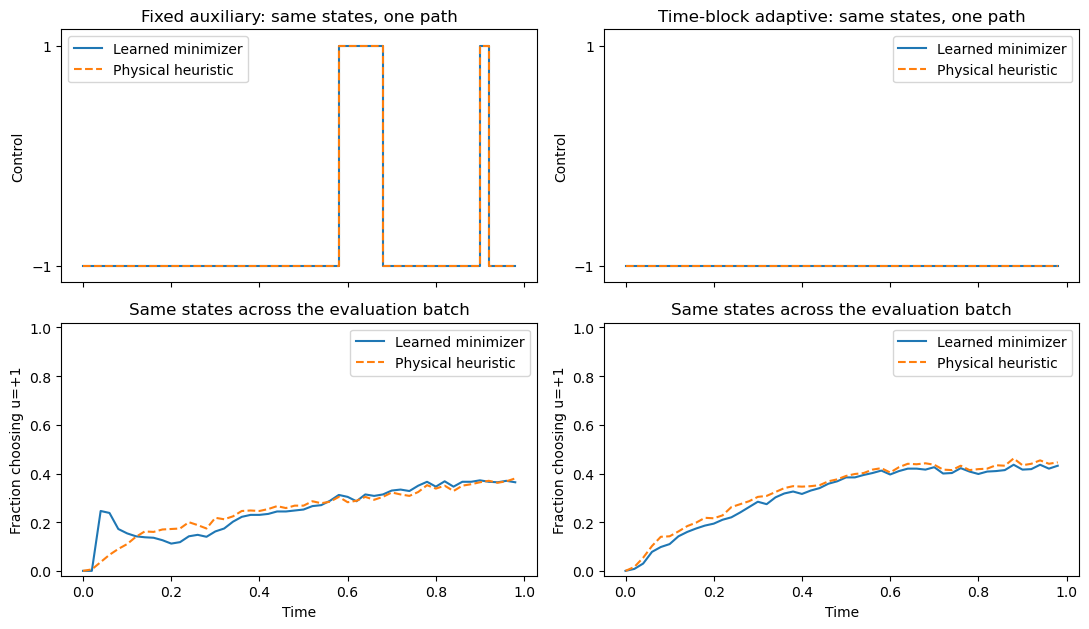

In [24]:
times = times_tensor.cpu().numpy()
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True)
for col, (name, learned, physical) in enumerate([
    ("Fixed auxiliary", fixed_controls, heuristic_on_fixed),
    ("Time-block adaptive", block_controls, heuristic_on_block),
]):
    axes[0, col].step(times, learned[0], where="post", label="Learned minimizer")
    axes[0, col].step(times, physical[0], where="post", linestyle="--", label="Physical heuristic")
    axes[0, col].set(title=f"{name}: same states, one path",
                     ylabel="Control", yticks=[-1, 1], ylim=(-1.15, 1.15))
    axes[0, col].legend()
    axes[1, col].plot(times, (learned == 1).mean(axis=0), label="Learned minimizer")
    axes[1, col].plot(times, (physical == 1).mean(axis=0), linestyle="--", label="Physical heuristic")
    axes[1, col].set(xlabel="Time", ylabel="Fraction choosing u=+1",
                     title="Same states across the evaluation batch", ylim=(-0.02, 1.02))
    axes[1, col].legend()
plt.tight_layout()
plt.show()

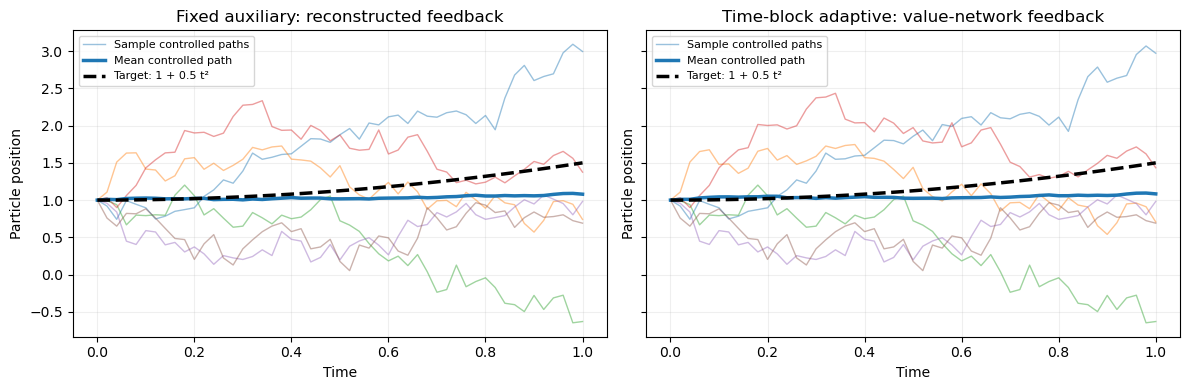

In [25]:
from two_bsde.dynamics import state_dynamics, stabilise_state


@torch.no_grad()
def rollout_fixed_feedback(model, innovations, num_references=8):
    cfg = model.config
    batch = innovations.shape[0]
    generator = torch.Generator(device=innovations.device).manual_seed(2030)
    reference_noise = math.sqrt(cfg.dt) * torch.randn(
        num_references, cfg.num_time_steps, cfg.observation_dim,
        dtype=innovations.dtype, device=innovations.device, generator=generator,
    )
    # Independent auxiliary references define a fixed, nonanticipating policy.
    references = model(reference_noise, return_paths=True)
    state = references["S_path"][0, 0].expand(batch, -1).clone()
    states, controls = [state], []
    model.hamiltonian_optimizer.reset()

    for step in range(cfg.num_time_steps):
        if step == 0:
            Z = model.initial_gradient().expand(batch, -1)
            Gamma = model.initial_gamma().expand(batch, -1, -1)
        else:
            ref_state = references["S_path"][:, step]
            ref_Z = references["Z_path"][:, step]
            ref_Gamma = references["Gamma_path"][:, step]
            displacement = state[:, None, :] - ref_state[None, :, :]
            midpoints = 0.5 * (state[:, None, :] + ref_state[None, :, :])
            _, mid_Gamma = model.blocks[step - 1](midpoints.reshape(-1, cfg.state_dim))
            mid_Gamma = mid_Gamma.reshape(batch, num_references, cfg.state_dim, cfg.state_dim)
            _, Gamma = model.blocks[step - 1](state)
            integrated_Gamma = (ref_Gamma[None] + 4 * mid_Gamma + Gamma[:, None]) / 6
            # D V(s) = Z_ref + integral Gamma(s_ref + a*(s-s_ref))*(s-s_ref) da.
            Z = (ref_Z[None] + torch.einsum(
                "bmij,bmj->bmi", integrated_Gamma, displacement
            )).mean(dim=1)
            Z = model.geometry.project_gradient(Z)

        _, control = model.hamiltonian_optimizer.minimise(state, Z, Gamma)
        drift, sigma, _ = state_dynamics(
            state, control, problem=model.problem, config=cfg, geometry=model.geometry
        )
        state = state + drift * cfg.dt + torch.einsum(
            "bia,ba->bi", sigma, innovations[:, step]
        )
        state, _ = stabilise_state(state, config=cfg)
        states.append(state)
        controls.append(control)
    return {"S_path": torch.stack(states, dim=1), "u_path": torch.stack(controls, dim=1)}


NUM_TRACKING_PATHS = 256
NUM_SHOWN_PATHS = 6
torch.manual_seed(2028)
tracking_innovations = math.sqrt(config.dt) * torch.randn(
    NUM_TRACKING_PATHS, config.num_time_steps, config.observation_dim,
    dtype=DTYPE, device=DEVICE,
)
fixed_tracking = rollout_fixed_feedback(fixed_model, tracking_innovations)
# This method bypasses forward hooks, so reset the time adapter explicitly.
block_model.hamiltonian_optimizer.reset()
block_tracking = block_model.rollout_policy(tracking_innovations)

tracking_times = np.linspace(0.0, config.horizon, config.num_time_steps + 1)
tracking_fig, tracking_axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, name, rollout in zip(tracking_axes, [
    "Fixed auxiliary: reconstructed feedback",
    "Time-block adaptive: value-network feedback",
], [fixed_tracking, block_tracking]):
    positions = rollout["S_path"][..., 0].detach().cpu().numpy()
    for i in range(min(NUM_SHOWN_PATHS, NUM_TRACKING_PATHS)):
        ax.plot(tracking_times, positions[i], alpha=0.45, linewidth=1,
                label="Sample controlled paths" if i == 0 else None)
    ax.plot(tracking_times, positions.mean(axis=0), color="tab:blue", linewidth=2.5,
            label="Mean controlled path")
    ax.plot(tracking_times, problem.target(tracking_times), "k--", linewidth=2.5,
            label="Target: 1 + 0.5 t²")
    ax.set(title=name, xlabel="Time", ylabel="Particle position")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
tracking_fig.tight_layout()
plt.show()